In [1]:
import ROOT
import pandas as pd
import numpy as np
import os
import sys
import ipynbname
from pathlib import Path

project_root = str(ipynbname.path().parent.parent)
sys.path.append(project_root)
project_root=Path(project_root)

from processing import SiphraAcquisition, MetadataLoader
from analysis import fit_peak_expbg

# Constants
BITS12 = 2**12
BITS9 = 2**9 # 512 typical number of bins used

# Energy emission peaks in MeV
Cs137_MeV = 0.662
Na22_MeV = [0.511, 1.275, 1.786]
Co60_MeV = [1.173, 1.332, 2,505]
Am241_MeV = 0.0595
# Background emission
K40_MeV = 1.460
Tl208_MEV = 2.614

colors = [
    ROOT.kRed + 1,
    ROOT.kBlue + 1,
    ROOT.kGreen + 2,
    ROOT.kOrange + 7,
    ROOT.kMagenta + 1,
    ROOT.kCyan + 1,
    ROOT.kViolet + 2,
    ROOT.kPink + 7,
    ROOT.kTeal + 3,
    ROOT.kAzure + 2,
    ROOT.kSpring + 5,
    ROOT.kRed,
    ROOT.kBlue
]
siphras = ['A', 'B']

In [2]:
files = sorted((project_root/'data/260528').glob('SUBT_*'))
acqs = [SiphraAcquisition(file) for file in files]
print(acqs)
#print(acqs)
#Abackground = acqs[12]
#Bbackground = acqs[25]
backgrounds =  acqs[0]
#calibrations = [acqs[0], acqs[13]]
acqs = acqs[1:13]
#Bacqs = acqs[12:]
#acqs = [Aacqs, Bacqs]
print(backgrounds)
#print(calibrations)
print(acqs)

[SIPHRAAcquisition(File: 'SUBT_01_CollimatedSource_SiphraAonly_Background_test'), SIPHRAAcquisition(File: 'SUBT_02_CollimatedSource_SiphraAonly_Cs137_2cm'), SIPHRAAcquisition(File: 'SUBT_03_CollimatedSource_SiphraAonly_Cs137_3cm'), SIPHRAAcquisition(File: 'SUBT_04_CollimatedSource_SiphraAonly_Cs137_4cm'), SIPHRAAcquisition(File: 'SUBT_05_CollimatedSource_SiphraAonly_Cs137_5cm'), SIPHRAAcquisition(File: 'SUBT_06_CollimatedSource_SiphraAonly_Cs137_6cm'), SIPHRAAcquisition(File: 'SUBT_07_CollimatedSource_SiphraAonly_Cs137_7cm'), SIPHRAAcquisition(File: 'SUBT_08_CollimatedSource_SiphraAonly_Cs137_8cm'), SIPHRAAcquisition(File: 'SUBT_09_CollimatedSource_SiphraAonly_Cs137_9cm'), SIPHRAAcquisition(File: 'SUBT_10_CollimatedSource_SiphraAonly_Cs137_10cm'), SIPHRAAcquisition(File: 'SUBT_11_CollimatedSource_SiphraAonly_Cs137_11cm'), SIPHRAAcquisition(File: 'SUBT_12_CollimatedSource_SiphraAonly_Cs137_12cm'), SIPHRAAcquisition(File: 'SUBT_13_CollimatedSource_SiphraAonly_Cs137_13cm')]
SIPHRAAcquisit

In [3]:
# Create histograms for background and each distance for both siphras. Create background subtracted histograms. 
hists = {}
distances_cm = list(range(2, 14))
siphra = 'A'
bg = backgrounds

#Background
hist_bg = ROOT.TH1F(f"{siphra}_Background", "", BITS12, 0 , BITS12)
hist_bg.Fill(bg['s']/len(bg.active_chs))
hist_bg.GetXaxis().SetTitle("ADC channel number")
hist_bg.GetYaxis().SetTitle(r"Normalized counts")
hists[f"{siphra}_Background"] = hist_bg

for sgnl, distance in zip(acqs, distances_cm):

    # Distance to B = 15 - distance to A
    print(distance)
        
    filepath = sgnl.filepath.stem

    # Signal
    hist_sgnl = ROOT.TH1F(f"{siphra}_{distance}cm_signal", "", BITS12, 0, BITS12)
    hist_sgnl.Fill(sgnl['s']/len(sgnl.active_chs))      
    hist_sgnl.Scale(bg.exposure/sgnl.exposure)
    
    # Clean spectrum
    hist_clean = hist_sgnl.Clone(f"{siphra}_{distance}cm_clean")
    hist_clean.Add(hist_bg, -1)
    
    for hist in [hist_sgnl, hist_clean]:
        hist.GetXaxis().SetTitle("ADC channel number")
        hist.GetYaxis().SetTitle(r"Normalized counts")
        
    hists[f"{siphra}_{distance}cm_signal"] = hist_sgnl      
    hists[f"{siphra}_{distance}cm_clean"] = hist_clean
    
    del hist_sgnl
    del hist_clean
del hist_bg

2
3
4
5
6
7
8
9
10
11
12
13


In [4]:
#Draw one histogram for each distance + siphra combination

if ROOT.gROOT.FindObject('cv1'):
    ROOT.gROOT.FindObject('cv1').Close()

Yinit = 0.82 # For stat boxes

cv1 = ROOT.TCanvas('cv1', 'cv1', 4800, 2400)
cv1.Divide(3, 4)
ROOT.gStyle.SetOptStat(11)
ROOT.gStyle.SetStatFontSize(0.03)
ROOT.gStyle.SetStatW(0.16)

lgds = [ROOT.TLegend(0.48, 0.61, 0.75, 0.83) for _ in range(22)]
 
for idx, distance in enumerate(distances_cm):
    lg = lgds[idx]
    cv1.cd(idx+1)
    cv1.cd(idx+1).SetLogy()
    
    bg = hists[f"{siphra}_Background"] 
    sgnl = hists[f"{siphra}_{distance}cm_signal"]         
    clean = hists[f"{siphra}_{distance}cm_clean"] 
    
    lg.AddEntry(sgnl, r"^{137}Cs Signal")
    lg.AddEntry(bg, "Background")
    lg.AddEntry(clean, r"^{137}Cs Background subtracted")
    
    sgnl.SetLineColor(colors[0])
    bg.SetLineColor(colors[1])
    clean.SetLineColor(colors[2])
    #sgnl.SetTitle(str(distance))
    #clean.SetTitle(f"SIPHRA {siphra} distance: {distance} cm")
    print(distance)
    sgnl.SetTitle(f"One-sided readout distance: {distance} cm")

    # Drw histograms
    sgnl.Draw("hist")
    bg.Draw("sames hist")
    clean.Draw("sames hist")
    
    ROOT.gPad.Update()
    lg.Draw()
    cv1.Draw()
    


2
3
4
5
6
7
8
9
10
11
12
13


In [5]:
#Plot all the subtracted histogram spectra in one plot.

if ROOT.gROOT.FindObject('cv2'):
    ROOT.gROOT.FindObject('cv2').Close()

Yinit = 0.82 # For stat boxes

cv2 = ROOT.TCanvas('cv2', 'cv2', 2400, 1200)
#cv2.Divide(2,1)

ROOT.gStyle.SetOptStat(11)
ROOT.gStyle.SetStatFontSize(0.03)
ROOT.gStyle.SetStatW(0.16)

lg = ROOT.TLegend(0.48, 0.61, 0.75, 0.83)

#cv2.cd(i+1)
cv2.SetLogy()


for idx, (distance) in enumerate(distances_cm):   
    
    clean = hists[f"{siphra}_{distance}cm_clean"] 
    lg.AddEntry(clean, f"Bg subtracted {distance} cm SIPHRA {siphra}")
    clean.SetLineColor(colors[idx])
    if idx ==0:
        clean.Draw("hist")
    else:
        clean.Draw("sames hist")
    ROOT.gPad.Update()
    
lg.Draw()   
cv2.Draw()

431.66326583316214
448.44317894312496
439.5422957231677
443.6124529294516
439.6519584949402
440.3461885058556
443.16923970732614
435.3559256504639
421.11208144348365
435.50119498866474
444.01644254660937
440.4630589157888
[]


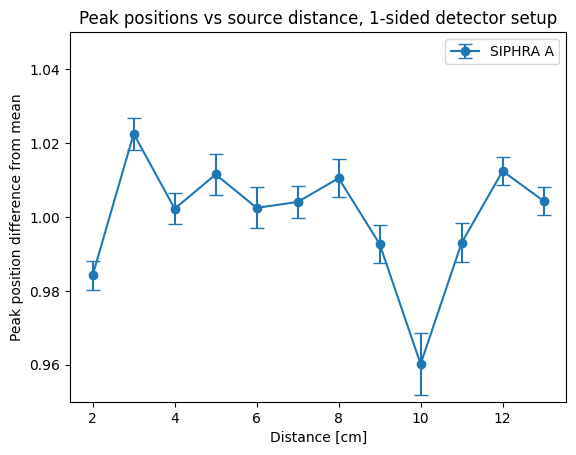

****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      154.408
NDf                       =          117
Edm                       =  9.63129e-10
NCalls                    =           94
Constant                  =      98.3406   +/-   2.00709     
Mean                      =      431.663   +/-   1.73382     
Sigma                     =      56.9518   +/-   2.8115       	 (limited)
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      123.663
NDf                       =          117
Edm                       =  4.34433e-08
NCalls                    =          106
Constant                  =      93.1267   +/-   1.95669     
Mean                      =      448.443   +/-   1.90548     
Sigma                     =      60.2855   +/-   3.40566      	 (limited)
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      107.948
NDf                   

In [6]:
#Plot the mean ADC value of the photopeak for each SIPHRA and distance. Include error bars.
#TODO: show as a percentage deviation from total mean? Like in Mozsis plot?

import matplotlib.pyplot as plt

distances_cm = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]

means_list = []
mean_avg_list = []
error_list = []
diff_avg_list = []

means = []
errors = []
for j, distance in enumerate(distances_cm):
    hist = hists[f"{siphra}_{distance}cm_clean"] 
    gaus_fit = ROOT.TF1("gaus_fit", "gaus", 380, 500)
    hist.Fit(gaus_fit, "R+S")
    
    mean = gaus_fit.GetParameter(1)
    error = gaus_fit.GetParError(1)
    print(mean)
    if mean >1:
        means.append(mean)
        errors.append(error)
#means_list.append(means)
mean_avg = np.mean(means)
diff_avg = [x / mean_avg for x in means]
diff_avg_errors = [e / mean_avg for e in errors]
#mean_avg_list.append(mean_avg)
error_list.append(errors)
#diff_avg_list.append(diff_avg)

print(diff_avg_list)




#for i, (means, errors, siphra) in enumerate(zip(diff_avg_list, error_list, siphras)):
plt.errorbar(
    distances_cm,
    diff_avg,
    yerr= diff_avg_errors,
    fmt='o-',        # 'o' means scatter points
    capsize=5,      # little caps on error bars
    label = f"SIPHRA {siphra}"
    #ecolor='black'
)


plt.legend()
plt.xlabel("Distance [cm]")
plt.ylabel("Peak position difference from mean")
plt.ylim(0.95, 1.05)
plt.title("Peak positions vs source distance, 1-sided detector setup")

plt.show()
        
        